# BSP project

*Giacomo Sacco 82389A*

Algorithm implemetation of the paper:

"A wavelet-based ECG delineation algorithm for 32-bit integer online processing" (2011) by Luigi Di Marco and Lorenzo Chiari

In [30]:
import numpy as np
import pywt
from scipy.signal import find_peaks, resample
import wfdb
import matplotlib.pyplot as plt
from ecg_utils import load_ecg, load_annotations, plot_ecg, plot_ecg_interactive, load_ecg_int

In [31]:
# MIT-BIH Arrhythmia Database record names
mit_bih_records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '217', '219', '220', '221',
    '222', '223', '228', '230', '231', '232', '233', '234'
]
current = 29
path = "../data/mit-bih-arrhythmia-database-1.0.0"
len(mit_bih_records)

48

In [32]:
ecg, fs, record = load_ecg_int(mit_bih_records[current], path)
annotations = load_annotations(mit_bih_records[current], path)

In [33]:
# Load QT Database records
qtdb_path = "../data/qt-database-1.0.0"
#ecg, fs, record = load_ecg_int("sel100", qtdb_path)


## Preprocessing
downsample to 250 sample/s

In [34]:
# downsample ecg signal to 250 Hz
new_fs = 250
ecg = resample(ecg, int(len(ecg) * new_fs / fs))
fs = new_fs

## DWT decomposition

In [35]:
def remove_group_delay(details):
    '''
    Remove group delay from detail coefficients. 
    Using 4.1 formula from the paper. 
    input: details - detail coefficents of the wavelet filter
    output: details - shifted version of the detail coefficents
    '''
    for k in details.keys():
        tau = 0
        # Sum of H filter delays
        for l in range(1, k):
            tau_H = -3 * 2**(l - 2)
            tau += tau_H
        # Add G filter delay once
        tau_G = -2**(k - 2)
        tau += tau_G
        print(f'level {k}: group delay = {tau} samples')
        details[k] = np.roll(details[k], int(np.ceil(tau)))
    return details

def integer_wavelet_transform(ecg_signal, levels=4):
    '''
    Perform Integer Wavelet Transform using the "algorithme à trous" method.
    input: ecg_signal - raw ECG signal
           levels - number of decomposition levels (default 4)
    output: details - dictionary of detail coefficients at each level
            approximation - final approximation coefficients
    '''
    # 32-bit integer conversion (to avoid overflow during summation)
    signal = np.array(ecg_signal, dtype=np.int32)

    # Base coefficients (Numerators from Table 1)
    h_coeffs = np.array([1, 7, 21, 35, 35, 21, 7, 1], dtype=np.int32)
    g_coeffs = np.array([-2, 2], dtype=np.int32)
    
    # Dictionary to store detail coefficients (d1, d2, d3, d4, ...)
    details = {}
    approximation = signal 
    
    # Loop for scales from 1 to 4 (2^1 to 2^4)
    for k in range(1, levels+1):
        # --- A. FILTER PREPARATION (ALGORITHME À TROUS) ---
        # At each scale k, insert 2^(k-1) - 1 zeros between coefficients
        step = 2**(k-1)
        
        # Create "dilated" filters with zeros (the "holes")
        h_k = np.zeros(len(h_coeffs) * step - (step-1), dtype=np.int32)
        h_k[::step] = h_coeffs
        # g_k is time-reversed version of g_coeffs because otherwise detail coefficients are inverted
        g_k = np.zeros(len(g_coeffs[::-1]) * step - (step-1), dtype=np.int32)
        g_k[::step] = g_coeffs[::-1]

        # --- B. CONVOLUTION (Shift & Add) ---
        # Calculate the next Approximation (A_k) using h_k
        # 'same' keeps the length the same (not decimated)
        a_next_num = np.convolve(approximation, h_k, mode='same')
        # Integer division via bit-shift: divided by 128 is shift >> 7
        a_next = np.right_shift(a_next_num, 7)
        
        # Calculate the Detail (d_k) using g_k
        # g has no divisor in Table 1, it is just differential [-2, 2]
        d_next = np.convolve(approximation, g_k, mode='same')
        
        # remove beginning and end artifacts due to convolution on detail coefficients
        mean_d = np.mean(d_next)
        d_next[:len(h_k)//2] = mean_d
        d_next[-(len(h_k)//2):] = mean_d

        details[k] = d_next
        approximation = a_next # The input for the next iteration is the current approximation
    
    details = remove_group_delay(details)

    return details, approximation

details, approximation = integer_wavelet_transform(ecg, 5)

level 1: group delay = -0.5 samples
level 2: group delay = -2.5 samples
level 3: group delay = -6.5 samples
level 4: group delay = -14.5 samples
level 5: group delay = -30.5 samples


(2.0, 5.0)

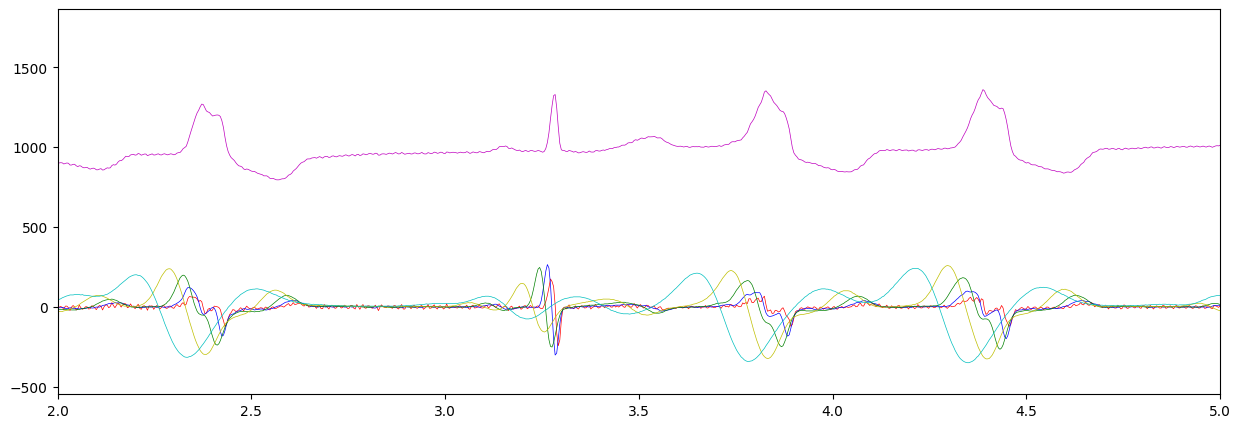

In [36]:
# Create time array
time = np.arange(len(ecg)) / fs

# Plot ECG signal
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(time, ecg, 'm-', linewidth=0.5, label='ECG')
ax.plot(time, details[1], 'r-', linewidth=0.5, label='ECG')
ax.plot(time, details[2], 'b-', linewidth=0.5, label='ECG')
ax.plot(time, details[3], 'g-', linewidth=0.5, label='ECG')
ax.plot(time, details[4], 'y-', linewidth=0.5, label='ECG')
ax.plot(time, details[5], 'c-', linewidth=0.5, label='ECG')
ax.set_xlim(2, 5)

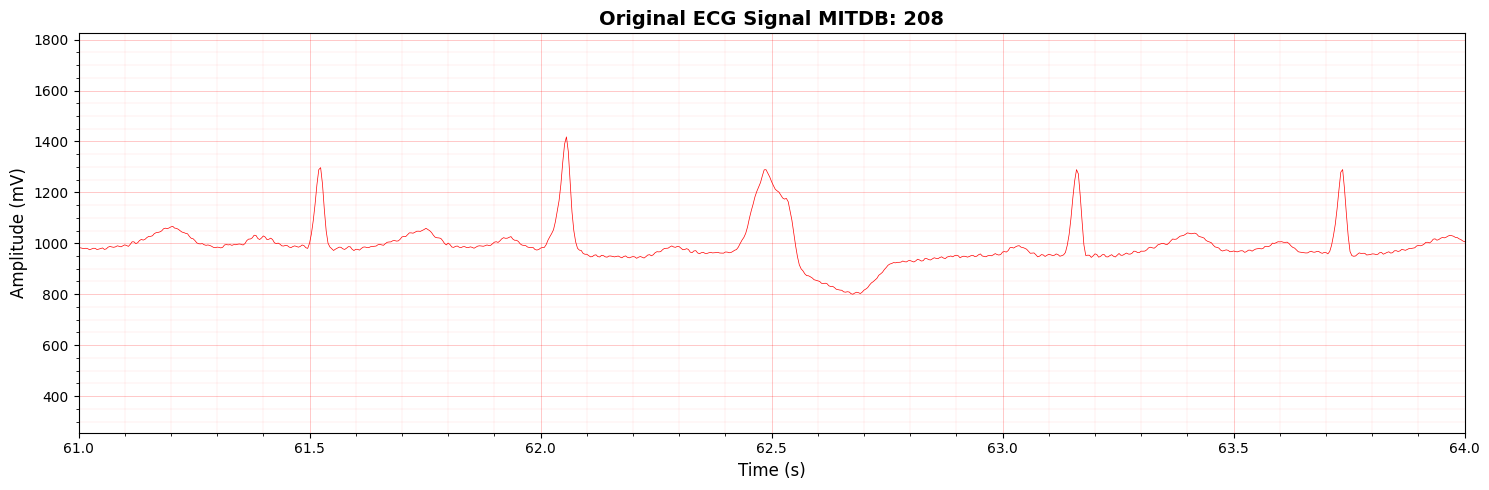

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz
1


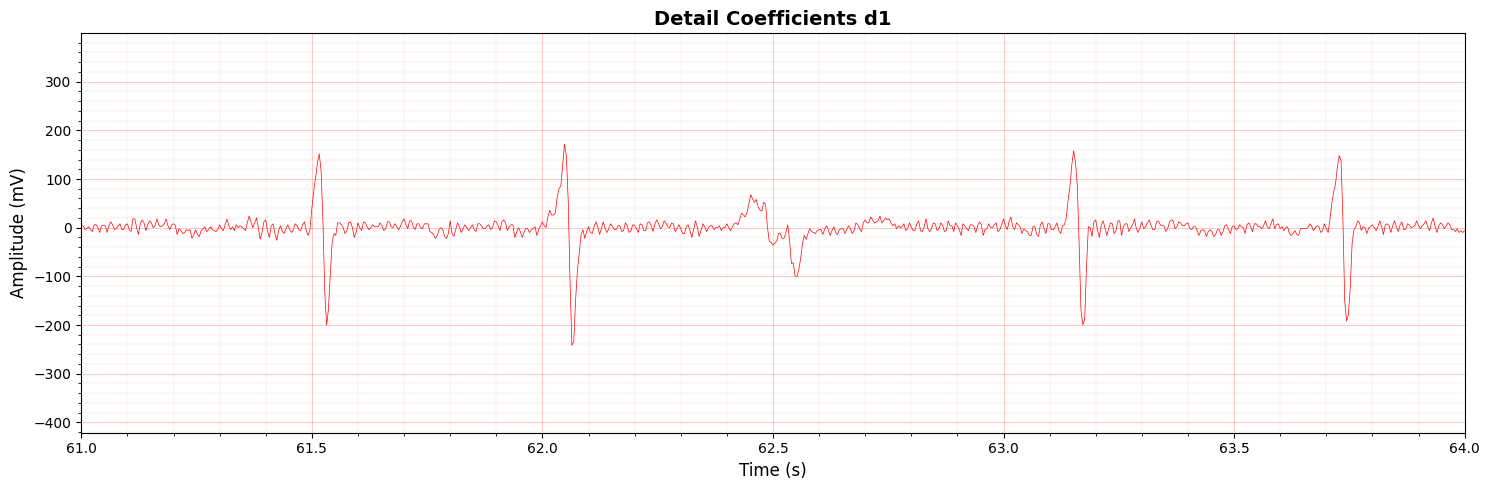

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz
2


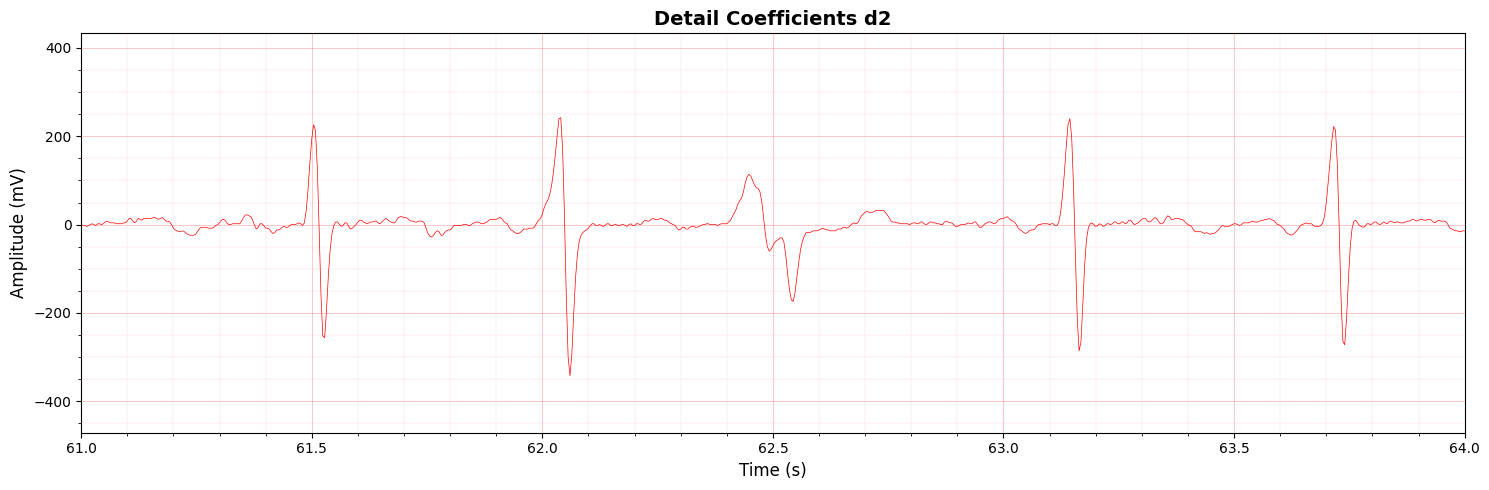

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz
3


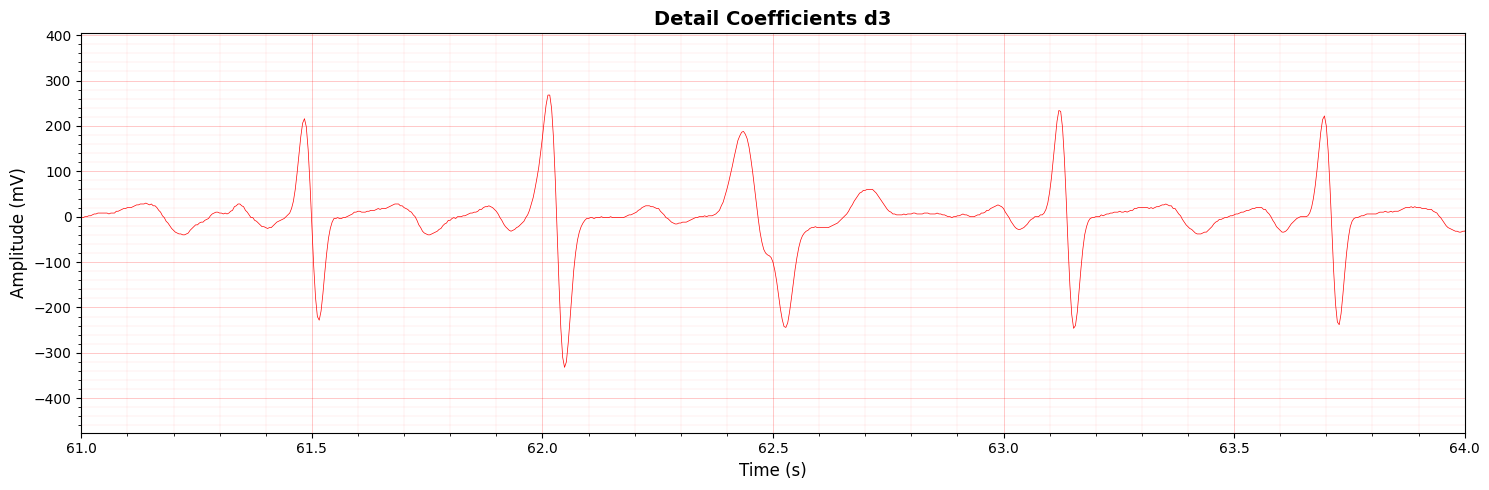

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz
4


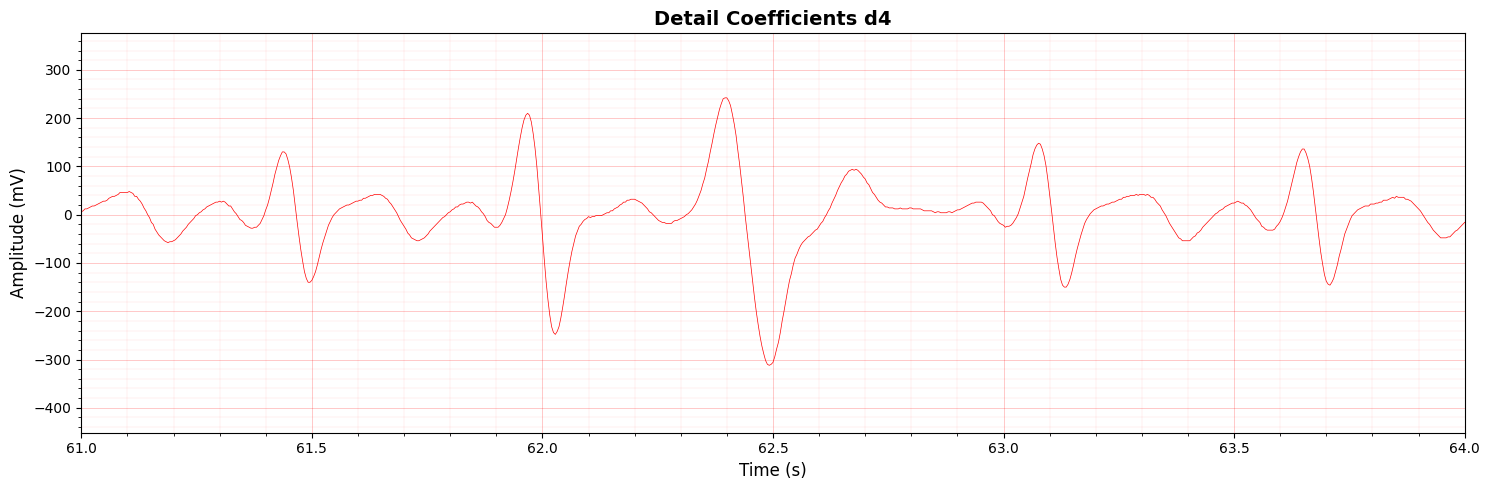

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz
5


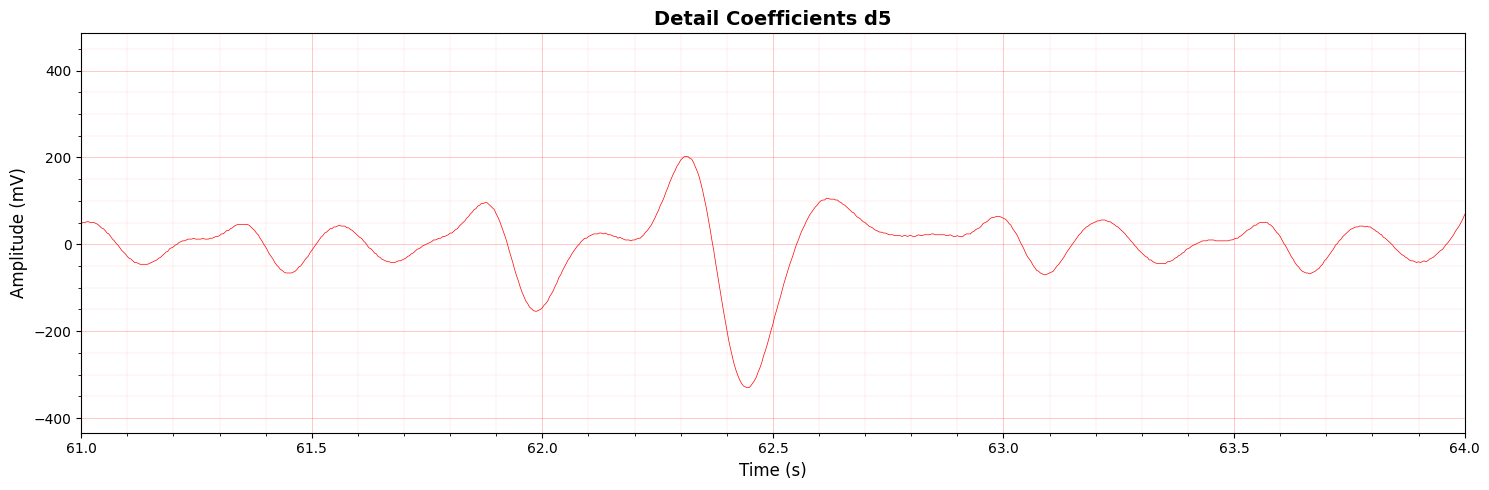

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


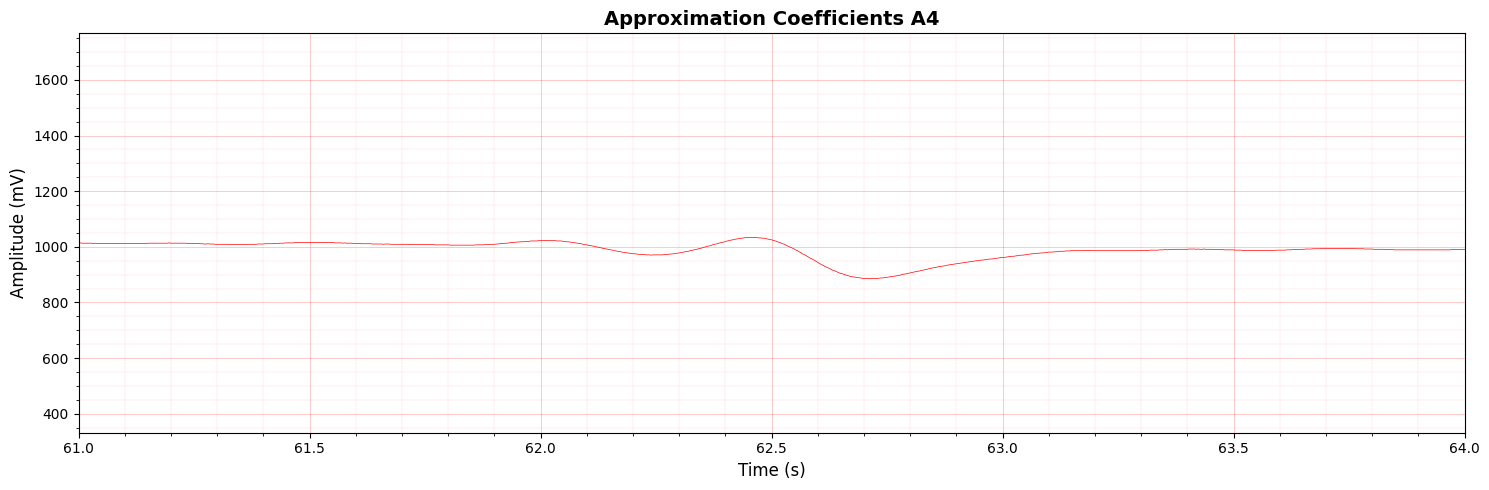

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


In [37]:
time_range = (61, 64)
plot_ecg(ecg, fs, time_range = time_range, title=f'Original ECG Signal MITDB: {mit_bih_records[current]}')
for level in details:
    print(level)
    plot_ecg(details[level], fs, time_range = time_range, title=f'Detail Coefficients d{level}')
plot_ecg(approximation, fs, time_range = time_range, title='Approximation Coefficients A4')

## Online QRS detection and P-QRS-T delineation

###  QRS-complex detection


In [38]:
def max_min_difference(signal):
    '''Calculate the difference between the maximum and minimum value in a vector'''
    max = np.max(signal)
    min = np.min(signal)
    delta = max - min
    return delta

def is_zero_crossing(signal, i):
    '''
    Calculate if two point are a zero-crossing. 
    If they are return the AMMp value, otherwise return 0.
    '''
    # Check if there is a zero crossing between i-1 and i
    if (signal[i-1] <= 0 and signal[i] > 0) or (signal[i-1] > 0 and signal[i] <= 0):
        # search left
        j = i - 1
        loc_max = abs(signal[j])
        while j > 0 and abs(signal[j-1]) >= loc_max:
            j -= 1
            loc_max = abs(signal[j])
        left_peak = abs(signal[j])
        left_peak_pos = j

        # search right
        j = i
        loc_max = abs(signal[j])
        while  j < len(signal)-1 and abs(signal[j+1]) >= loc_max:
            j += 1
            loc_max = abs(signal[j])
        right_peak = abs(signal[j])
        right_peak_pos = j
        # calculate Adjacent Modulus Maxima pair
        AMMp = left_peak + right_peak
    else:
        AMMp = 0
        left_peak_pos = None
        right_peak_pos = None
    return AMMp, left_peak_pos, right_peak_pos

def QRS_detection(details, fs):
    '''
    Docstring for QRS_detection
    
    :param details: detail coefficents from WT
    :param fs: sampling frequency
    '''
    # detail levels used
    d2=details[2]
    d3=details[3]
    qrs_positions = []                  # found qrs postions
    qrs_d2_delta = []                   # qrs min-max delta on d^2
    qrs_d3_delta = []                   # qrs min-max delta on d^3
    qrs_d2_peaks_pos = []               # qrs peak positions on d^2
    qrs_found = 0                       # number of QRS found
    deltaWQRS = np.right_shift(fs, 2)   # observation window = 250 ms
    deltaW100 = int(fs * 0.1)           # half-window samples number for detection rules
    i_zc = int(1)                       # index for zero-crossing search
    signal_length = len(d2)

     # search zero-crossings in detail level 2^2
    while i_zc < signal_length:
        AMMp, left_peak_pos, right_peak_pos = is_zero_crossing(d2, i_zc)   # Adjacent Modulus Maxima pair
        # if zero-crossing (ZCs) is found (AMMp>0) start looking for 
        # better ZCs (bigger AMMp) in the observation window
        if AMMp > 0:
            j_zc = i_zc + 1
            # iterate in the observation window looking for better QRS-candidates
            while j_zc < i_zc + deltaWQRS and j_zc < signal_length:
                AMMp_new, left_peak_pos_new, right_peak_pos_new = is_zero_crossing(d2, j_zc)
                # if a bigger AMMp is found, restart the obs. window
                if AMMp_new > AMMp:
                    AMMp = AMMp_new
                    left_peak_pos = left_peak_pos_new
                    right_peak_pos = right_peak_pos_new
                    i_zc = j_zc # new QRS candidate found
                else:
                    j_zc += 1

            # QRS candidate decision  
            delta_window = max(0, i_zc-deltaW100), min(signal_length-1, i_zc+deltaW100)
            e_start = max(0, qrs_found-4)
            zc_d2_delta = max_min_difference(d2[delta_window[0]:delta_window[1]])
            epsilon_d2 = np.right_shift(11 * sum(qrs_d2_delta[e_start:qrs_found]), 7)
            # first test on d^2
            if zc_d2_delta > epsilon_d2:
                zc_d3_delta = max_min_difference(d3[delta_window[0]:delta_window[1]])
                epsilon_d3 = np.right_shift(11 * sum(qrs_d3_delta[e_start:qrs_found]), 7)
                # second test on d^3
                if zc_d3_delta > epsilon_d3:
                    # QRS-candidate ACCEPTED
                    qrs_positions.append(np.int32(i_zc))
                    qrs_d2_delta.append(zc_d2_delta)
                    qrs_d3_delta.append(zc_d3_delta)
                    qrs_d2_peaks_pos.append((left_peak_pos, right_peak_pos))
                    qrs_found += 1
            i_zc += deltaWQRS + 1
        else:
            i_zc += 1
    #return qrs_positions[4:]
    return qrs_positions, qrs_d2_peaks_pos

r_peaks, qrs_d2_peaks_pos = QRS_detection(details, fs)

###  QRS-complex delineation (offset/offset)

In [39]:
def is_local_max(signal, i):
    if i <= 0 or i >= len(signal) - 1:
        return False
    val = abs(signal[i])
    return val > abs(signal[i-1]) and val >= abs(signal[i+1])

def QRS_delineation(details, fs, r_peaks, qrs_d2_peaks_pos):
    d2 = details[2]
    fixed_window = fs * 0.120  # 120 ms fixed window
    QRS_on = []
    QRS_off = []

    for key, qrs_pos in enumerate(r_peaks):
        npre = qrs_d2_peaks_pos[key][0]
        npost = qrs_d2_peaks_pos[key][1]

        d2_npre = int(abs(d2[npre]))
        d2_npost = int(abs(d2[npost]))
        
        # onset search
        e1_onset = np.right_shift(d2_npre + d2_npost, 5) # divide by 32 using bit-shift
        e2_onset = np.right_shift(d2_npre + d2_npost, 4) # divide by 16 using bit-shift
        
        i = npre
        search_e1 = True          # search for e1 crossing
        search_onset = True       # search for onset
        
        onset = None
        candidate_onset = None
        n_left = None

        window_end = max(0, i - fixed_window)
        while search_onset and i > window_end:
            mod_d2i = abs(d2[i])

            if search_e1 and mod_d2i <= e1_onset:
                candidate_onset = i
                search_e1 = False

            if is_local_max(d2, i):
                if mod_d2i <= e2_onset:
                    n_left = i
                    search_onset = False
                else:
                    n_left = i
            i -= 1

        if n_left is None:
            if candidate_onset is not None:
                onset = candidate_onset
            else:
                onset = window_end

        # if onset not found, search for e3 crossing
        if onset is None:
            e3_onset = np.right_shift(abs(int(d2[n_left])), 2) # divide by 4 using bit-shift
            i = n_left
            while onset is None and i > window_end:
                mod_d2i = abs(d2[i])
                if mod_d2i < e3_onset:
                    onset = i
                i -= 1
            onset = window_end if i <= window_end else onset

        QRS_on.append(np.int32(onset))
        #print(f'QRS at {qrs_pos/fs:.3f} s: onset at {(onset-qrs_pos)/fs:.3f} s')

        # offset search
        e1_offset = np.right_shift(d2_npost, 2) # divide by 4 using bit-shift
        e2_offset = np.right_shift(d2_npost, 3) # divide by 8 using bit-shift
        
        i = npost
        search_e1 = True          # search for e1 crossing
        search_offset = True       # search for offset
        
        offset = None
        candidate_offset = None
        n_right = None

        window_end = min(len(d2) - 1, i + fixed_window)
        while search_offset and i < window_end:
            mod_d2i = abs(d2[i])

            if search_e1 and mod_d2i <= e1_offset:
                candidate_offset = i
                search_e1 = False

            if is_local_max(d2, i):
                if mod_d2i <= e2_offset:
                    n_right = i
                    search_offset = False
                else:
                    n_right = i
            i += 1

        if n_right is None:
            if candidate_offset is not None:
                offset = candidate_offset
            else:
                offset = window_end

        # if offset not found, search for e3 crossing
        if offset is None:
            e3_offset = np.right_shift(abs(int(d2[n_right])), 2) # divide by 4 using bit-shift
            i = n_right
            while offset is None and i < window_end:
                mod_d2i = abs(d2[i])
                if mod_d2i < e3_offset:
                    offset = i
                i += 1
            offset = window_end if i >= window_end else offset

        #print(f'QRS at {qrs_pos/fs:.3f} s: offset at {(offset-qrs_pos)/fs:.3f} s')
        QRS_off.append(np.int32(offset))

    return QRS_on, QRS_off

QRS_onset, QRS_offset = QRS_delineation(details, fs, r_peaks, qrs_d2_peaks_pos)


### P wave delineation (mono & biphasic)

In [ ]:
    def interbeat_interval(r_peaks, pos):
        """return half the samples distance between the actual R peak and the precedent"""
        if pos > 1 and pos < len(r_peaks):
            return np.right_shift(r_peaks[pos] - r_peaks[pos-1], 1)
        else:
            return np.inf
        
    def biphasic_first_condition(d3, n_pre, n_post):
        """application of the (6.1) condition (from the paper) for a p_peak to be bi-phasic"""
        d3_n_post_mul2 = 2 * abs(d3[n_post])
        d3_n_post_div2 = np.right_shift(abs(d3[n_post]), 1)
        d3_n_pre = abs(d3[n_pre])

        if d3_n_post_div2 <= d3_n_pre and d3_n_pre <= d3_n_post_mul2:
            return True
        else:
            return False
        
    def biphasic_second_condition(AMMp_P, AMMp_bi):
        """application of the (6.2) condition (from the paper) for a p_peak to be bi-phasic"""
        if AMMp_bi > np.right_shift(3 * AMMp_P, 2):
            return True
        else:
            return False


    def P_wave_delineation(details, fs, QRS_onset, r_peaks):
        d3 = details[3]
        p_peaks = []
        p_onsets = []
        p_offsets = []
        max_window = int(fs * 0.3)  # 300 ms maximum window

        # Diagnostic counters
        no_zero_crossings = 0
        no_peak_found = 0
        onset_failed = 0
        offset_failed = 0

        # find P wave
        for i_qrs, qrs_onset in enumerate(QRS_onset):
            ibi = interbeat_interval(r_peaks, i_qrs)
            fixed_window = min(ibi, max_window)
            zero_crossings = {}
            # save all the zc in the window
            for i in range(qrs_onset-fixed_window, qrs_onset):
                AMMp, left_peak_pos, right_peak_pos = is_zero_crossing(d3, i)
                if AMMp > 0:
                    zero_crossings.update({i: {"AMMp": AMMp, "n_pre": left_peak_pos, "n_post": right_peak_pos}})
            # find P peak
            if len(zero_crossings) > 0: 
                p_peak_minpos = qrs_onset - fixed_window + 0.1*fs
                AMMp = 0
                p_peak = n_pre = n_post = None
                for zc, values in zero_crossings.items():
                    if zc > p_peak_minpos and values["AMMp"] > AMMp:
                        p_peak = zc
                        n_pre = values["n_pre"]
                        n_post = values["n_post"]
                        AMMp = values["AMMp"]
                # if a P peak was found        
                if p_peak is not None:
                    # Is it bi-phasic?
                    if biphasic_first_condition(d3, n_pre, n_post):
                        # check if it is LEFT bi-phasic
                        # check if there is a zc max 100ms before the peak 
                        left_peak_window = range(int(p_peak - 0.1 * fs), p_peak)
                        for zc, values in zero_crossings.items():
                            if zc in left_peak_window and biphasic_first_condition(d3, values["n_pre"], values["n_post"]):
                                if biphasic_second_condition(AMMp, values["AMMp"]):
                                    n_pre = values["n_pre"]
                        ## check if it is RIGHT bi-phasic
                        # check if there is a zc max 100ms before the peak 
                        right_peak_window = range(p_peak, int(p_peak + 0.1 * fs))
                        for zc, values in zero_crossings.items():
                            if zc in right_peak_window and biphasic_first_condition(d3, values["n_pre"], values["n_post"]):
                                if biphasic_second_condition(AMMp, values["AMMp"]):
                                    n_post = values["n_post"]
                    
                    # find P onset
                    p_onset_min = qrs_onset-fixed_window
                    i = n_pre
                    thresh_onset = np.right_shift(abs(d3[n_pre]), 2)     # (6.3) threshold: |d3(n_pre)|/4
                    candidate_onset = None
                    while i > p_onset_min and candidate_onset is None:
                        if abs(d3[i]) < thresh_onset:
                            candidate_onset = i
                        i -= 1

                    # find P offset
                    p_offset_max = qrs_onset
                    i = n_post
                    thresh_offset = np.right_shift(35*abs(d3[n_post]), 6)    # (6.4) threshold: 35*|d3(n_post)|/64
                    candidate_offset = None
                    while i < p_offset_max and candidate_offset is None:
                        if abs(d3[i]) < thresh_offset:
                            candidate_offset = i
                        i += 1

                    if candidate_offset and candidate_onset:
                        p_peaks.append(p_peak)
                        p_onsets.append(candidate_onset)
                        p_offsets.append(candidate_offset)
                    else:
                        p_peaks.append(None)
                        p_onsets.append(None)
                        p_offsets.append(None)
                        if not candidate_onset:
                            onset_failed += 1
                        if not candidate_offset:
                            offset_failed += 1
                else:
                    p_peaks.append(None)
                    p_onsets.append(None)
                    p_offsets.append(None)
                    no_peak_found += 1
            else:
                p_peaks.append(None)
                p_onsets.append(None)
                p_offsets.append(None)
                no_zero_crossings += 1

        print(f"Number of QRS delineation succeded: {len(QRS_onset)}")
        print(f"Number of P-waves delineation succeded: {sum(1 for p in p_peaks if p is not None)}")
        print(f"\nDiagnostic breakdown:")
        print(f"  - No zero crossings found: {no_zero_crossings}")
        print(f"  - Zero crossings found but no valid peak: {no_peak_found}")
        print(f"  - Peak found but onset search failed: {onset_failed}")
        print(f"  - Peak found but offset search failed: {offset_failed}")
        return p_peaks, p_onsets, p_offsets
                
    p_peaks, p_onsets, p_offset = P_wave_delineation(details, fs, QRS_onset, r_peaks)

Number of QRS delineation succeded: 2942
Number of P-waves delineation succeded: 790

Diagnostic breakdown:
  - No zero crossings found: 1
  - Zero crossings found but no valid peak: 16
  - Peak found but onset search failed: 398
  - Peak found but offset search failed: 2043


### T detection (mono & biphasic)

In [41]:
def T_wave_delineation(details, fs, QRS_offsets, r_peaks):
    d3 = details[3]
    DW80 = int(0.08 * fs)
    t_peaks = []
    t_offsets = []
    t_ends = []
    # i = QRS counter
    # j = sample in the current window
    for i in range(1, len(QRS_offsets)):
        t_peak = t_off = t_end = None
        RR = r_peaks[i] - r_peaks[i-1]
        T_win = (QRS_offsets[i-1] + DW80, QRS_offsets[i-1] + np.right_shift(19*RR, 5))
        Tpeak_win = (T_win[0], QRS_offsets[i-1] + np.right_shift(RR, 1))
        # save all the zero crossings in the window
        zcs = {}
        max_zc_AMMp = - np.inf
        prev_peak = None
        next_peak = None
        
        for j in range(Tpeak_win[0], Tpeak_win[1]):
            AMMp, left_peak_pos, right_peak_pos = is_zero_crossing(d3, j)
            if AMMp > 0:
                zcs.update({j: {"AMMp": AMMp, "n_pre": left_peak_pos, "n_post": right_peak_pos}})
                if max_zc_AMMp < AMMp:
                    prev_peak = t_peak          # save the previous peak before updating
                    t_peak = j
                    max_zc_AMMp = AMMp
                    next_peak = None            # reset next_peak when we find a new max
                elif t_peak is not None and next_peak is None:
                    next_peak = j               # first peak after the maximum
    
        if t_peak:
            # if the t wave is (left) bi-phasic
            bi_thresh_left = np.right_shift(51*zcs[t_peak]["AMMp"], 6)
            if prev_peak is not None and zcs[prev_peak]["AMMp"] > bi_thresh_left:
                t_off = t_peak
                t_peak = prev_peak     # the first peak is always the main one
                # calculate T end
                n_post = zcs[t_off]["n_post"]
                thresh_end = np.right_shift(19*abs(d3[n_post]), 6)
                j = n_post
                while j < T_win[1] and t_end is None:
                    if abs(d3[j]) < thresh_end:
                        t_end = j
                    j += 1
            # if the t wave is (right) bi-phasic or mono-phasic
            else:
                # find t offset
                n_post = zcs[t_peak]["n_post"]
                thresh_off = np.right_shift(19*abs(d3[n_post]), 6)
                j = n_post
                while j < T_win[1] and t_off is None:
                    if abs(d3[j]) < thresh_off:
                        t_off = j
                    j += 1
                # if there is a right peak
                if next_peak is not None:
                    # if that peak is big enough then it is bi-phasic
                    bi_thresh_right = np.right_shift(zcs[t_peak]["AMMp"], 1)
                    if zcs[next_peak]["AMMp"] >= bi_thresh_right:
                        # find t end after the second peak
                        n_post = zcs[next_peak]["n_post"]
                        thresh_end = np.right_shift(19*abs(d3[n_post]), 6)
                        j = n_post
                        while j < T_win[1] and t_end is None:
                            if abs(d3[j]) < thresh_end:
                                t_end = j
                            j += 1
        t_peaks.append(t_peak)
        t_offsets.append(t_off)
        t_ends.append(t_end)
        
    return t_peaks, t_offsets, t_ends

t_peaks, t_offsets, t_ends =T_wave_delineation(details, fs, QRS_offset, r_peaks)

## Results

In [42]:
# Analyze the detection results
total_qrs = len(r_peaks)
total_p = sum(1 for p in p_peaks if p is not None)
total_t = sum(1 for t in t_peaks if t is not None)

print("=" * 60)
print("ECG DELINEATION RESULTS")
print("=" * 60)
print(f"Record: {mit_bih_records[current]}")
print(f"Sampling frequency: {fs} Hz")
print(f"Signal duration: {len(ecg)/fs:.2f} seconds")
print("-" * 60)
print(f"QRS complexes detected: {total_qrs}")
print(f"P waves detected: {total_p} ({total_p/total_qrs*100:.1f}%)")
print(f"T waves detected: {total_t} ({total_t/total_qrs*100:.1f}%)")
print("-" * 60)

# Calculate average durations
qrs_durations = [(QRS_offset[i] - QRS_onset[i]) / fs * 1000 for i in range(len(QRS_onset))]
p_durations = [(p_offset[i] - p_onsets[i]) / fs * 1000 for i, p in enumerate(p_offset) if p is not None and p_onsets[i] is not None]

print(f"Average QRS duration: {np.mean(qrs_durations):.1f} ± {np.std(qrs_durations):.1f} ms")
if len(p_durations) > 0:
    print(f"Average P wave duration: {np.mean(p_durations):.1f} ± {np.std(p_durations):.1f} ms")

# Calculate heart rate
if len(r_peaks) > 1:
    rr_intervals = np.diff(r_peaks) / fs
    heart_rate = 60 / np.mean(rr_intervals)
    print(f"Average heart rate: {heart_rate:.1f} bpm")
print("=" * 60)

ECG DELINEATION RESULTS
Record: 208
Sampling frequency: 250 Hz
Signal duration: 1805.55 seconds
------------------------------------------------------------
QRS complexes detected: 2942
P waves detected: 790 (26.9%)
T waves detected: 2920 (99.3%)
------------------------------------------------------------
Average QRS duration: 191.2 ± 61.8 ms
Average P wave duration: 137.1 ± 35.8 ms
Average heart rate: 97.7 bpm


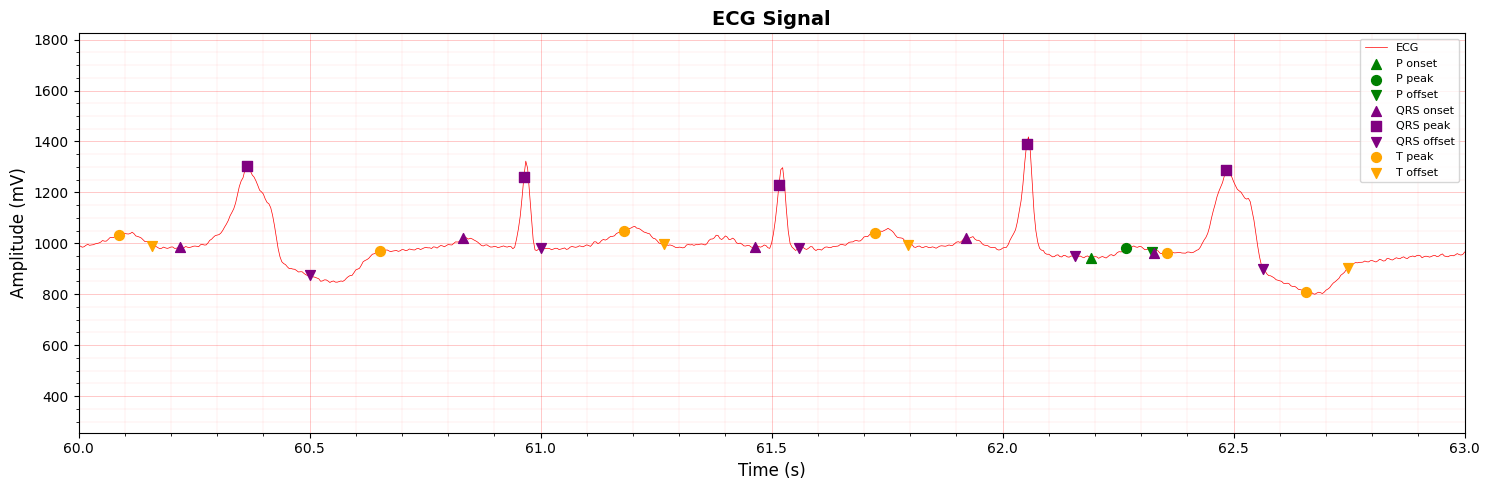

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


In [43]:
qrs_events={'onset': QRS_onset, 'offset': QRS_offset, 'peak': r_peaks}
p_events={'onset': p_onsets, 'offset': p_offset, 'peak': p_peaks}
t_events={'peak': t_peaks, 'offset': t_offsets, 'end': t_ends}

plot_ecg(ecg, fs, time_range=(60, 63), qrs_events=qrs_events, p_events=p_events, t_events=t_events)